# Aqua MODIS Chlorophyll-a: Arabian Sea exploration (2023)
Data: `MODISA_L3m_CHL`, monthly, 4 km. Region: 60-72°E, 20-27°N.

## 1. Setup aur data load

In [1]:
import os, glob
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

WEST, SOUTH, EAST, NORTH = 60, 20, 72, 27
CACHE = "chl_arabian_sea_2023.nc"

def open_any(f):
    for eng in ("netcdf4", "h5netcdf"):
        try:
            return xr.open_dataset(f, engine=eng)
        except Exception:
            pass
    raise RuntimeError(f"Cannot open {f}")

if os.path.exists(CACHE):
    chl = xr.open_dataarray(CACHE).load()
    print("Loaded from", CACHE)
else:
    parts = []
    for f in sorted(glob.glob("./ocean_data/*.nc")):
        ds = open_any(f)
        sub = ds["chlor_a"].sel(lat=slice(NORTH, SOUTH), lon=slice(WEST, EAST)).load()
        ym = os.path.basename(f).split(".")[1]          # 20230101_20230131
        date = np.datetime64(f"{ym[:4]}-{ym[4:6]}-01")
        parts.append(sub.expand_dims(time=[date]))
        ds.close()
    chl = xr.concat(parts, dim="time")
    chl.to_netcdf(CACHE)
    print("Built from raw files and saved", CACHE)

chl

Built from raw files and saved chl_arabian_sea_2023.nc


<xarray.DataArray 'chlor_a' (time: 12, lat: 168, lon: 288)> Size: 2MB
array([[[       nan,        nan,        nan, ...,        nan,
                nan,        nan],
        [       nan,        nan,        nan, ...,        nan,
                nan,        nan],
        [       nan,        nan,        nan, ...,        nan,
                nan,        nan],
        ...,
        [0.6634486 , 0.64998716, 0.7070242 , ..., 3.6113803 ,
         3.6203043 , 3.6950552 ],
        [0.7966986 , 0.7093575 , 0.69074863, ..., 3.5011828 ,
         3.5597322 , 3.6197088 ],
        [0.55023474, 0.62183195, 0.61150885, ..., 3.4578154 ,
         3.5050333 , 3.5456624 ]],

       [[       nan,        nan,        nan, ...,        nan,
                nan,        nan],
        [       nan,        nan,        nan, ...,        nan,
                nan,        nan],
        [       nan,        nan,        nan, ...,        nan,
                nan,        nan],
...
        [0.55641574, 0.51231873, 0.45442408, ..., 2.777033  ,
         2.9034083 , 2.6115859 ],
        [0.48745388, 0.45788902, 0.39115748, ..., 2.6691263 ,
         2.4364858 , 2.1509988 ],
        [0.4278799 , 0.46639675, 0.35888377, ..., 2.5840359 ,
         2.631661  , 2.160769  ]],

       [[       nan,        nan,        nan, ...,        nan,
                nan,        nan],
        [       nan,        nan,        nan, ...,        nan,
                nan,        nan],
        [       nan,        nan,        nan, ...,        nan,
                nan,        nan],
        ...,
        [0.5717251 , 0.6007705 , 0.61371434, ..., 3.220863  ,
         3.2350357 , 3.3317974 ],
        [0.56554854, 0.59419984, 0.6230335 , ..., 3.1601825 ,
         3.2018902 , 3.295651  ],
        [0.57918537, 0.6054752 , 0.6141372 , ..., 3.1250234 ,
         3.2116377 , 3.2589338 ]]], shape=(12, 168, 288), dtype=float32)
Coordinates:
  * time     (time) datetime64[s] 96B 2023-01-01 2023-02-01 ... 2023-12-01
  * lat      (lat) float32 672B 26.98 26.94 26.9 26.85 ... 20.1 20.06 20.02
  * lon      (lon) float32 1kB 60.02 60.06 60.1 60.15 ... 71.85 71.9 71.94 71.98
Attributes:
    long_name:      Chlorophyll Concentration, OCI Algorithm
    units:          mg m^-3
    standard_name:  mass_concentration_of_chlorophyll_in_sea_water
    valid_min:      0.001
    valid_max:      100.0
    reference:      Hu, C., Feng, L., Lee, Z., Franz, B. A., Bailey, S. W., W...
    display_scale:  log
    display_min:    0.01
    display_max:    20.0

## 2. Data ka basic jaiza

In [2]:
print("Shape (time, lat, lon):", chl.shape)
print("Period:", str(chl.time.values[0])[:7], "to", str(chl.time.values[-1])[:7])
print("Lat range:", round(float(chl.lat.min()), 2), "-", round(float(chl.lat.max()), 2))
print("Lon range:", round(float(chl.lon.min()), 2), "-", round(float(chl.lon.max()), 2))
print(f"Valid pixels: {chl.notnull().mean().item()*100:.1f}%  (baqi NaN = zameen / badal)")
print()
print(chl.to_series().describe(percentiles=[.05, .25, .5, .75, .95]).round(3))

Shape (time, lat, lon): (12, 168, 288)
Period: 2023-01 to 2023-12
Lat range: 20.02 - 26.98
Lon range: 60.02 - 71.98
Valid pixels: 43.5%  (baqi NaN = zameen / badal)

count    252543.000
mean          1.577
std           2.342
min           0.093
5%            0.185
25%           0.359
50%           0.707
75%           1.891
95%           5.627
max          77.375
Name: chlor_a, dtype: float64


## 3. Values ka distribution
Chlorophyll ka distribution **log-normal** hota hai, isliye x-axis log scale par.

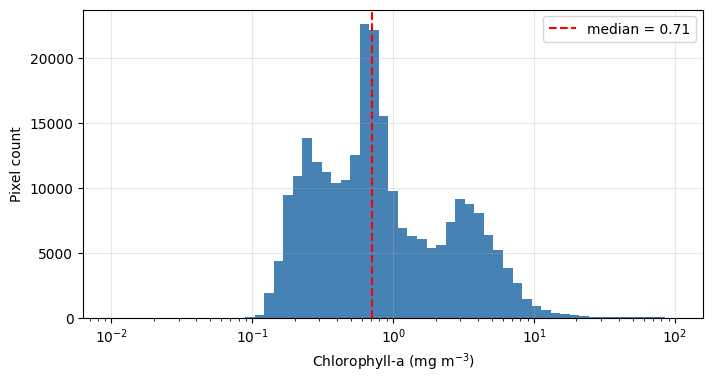

In [3]:
vals = chl.values.ravel()
vals = vals[~np.isnan(vals)]

plt.figure(figsize=(8, 4))
plt.hist(vals, bins=np.logspace(-2, 2, 60), color="steelblue")
plt.xscale("log")
plt.axvline(np.median(vals), color="red", ls="--", label=f"median = {np.median(vals):.2f}")
plt.xlabel("Chlorophyll-a (mg m$^{-3}$)")
plt.ylabel("Pixel count")
plt.legend(); plt.grid(alpha=0.3)
plt.show()

## 4. Har mahine ka map

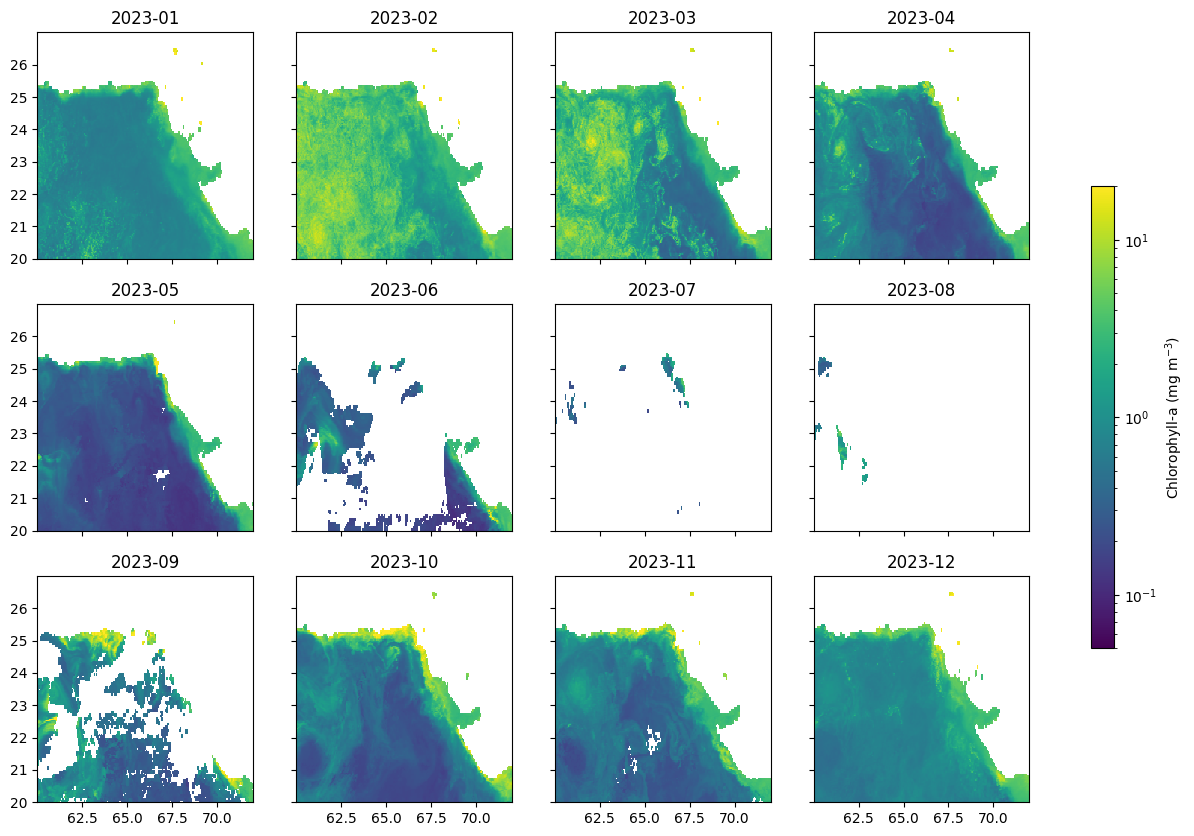

In [4]:
norm = LogNorm(vmin=0.05, vmax=20)
fig, axes = plt.subplots(3, 4, figsize=(16, 10), sharex=True, sharey=True)
for i, ax in enumerate(axes.flat):
    im = chl.isel(time=i).plot(ax=ax, cmap="viridis", norm=norm, add_colorbar=False)
    ax.set_title(str(chl.time.values[i])[:7])
    ax.set_xlabel(""); ax.set_ylabel("")
fig.colorbar(im, ax=axes, shrink=0.6, label="Chlorophyll-a (mg m$^{-3}$)")
plt.show()

## 5. Mean vs median aur valid pixels
Coast ke qareeb ki bohat zyada values mean ko oopar kheench leti hain, isliye median bhi dekho.

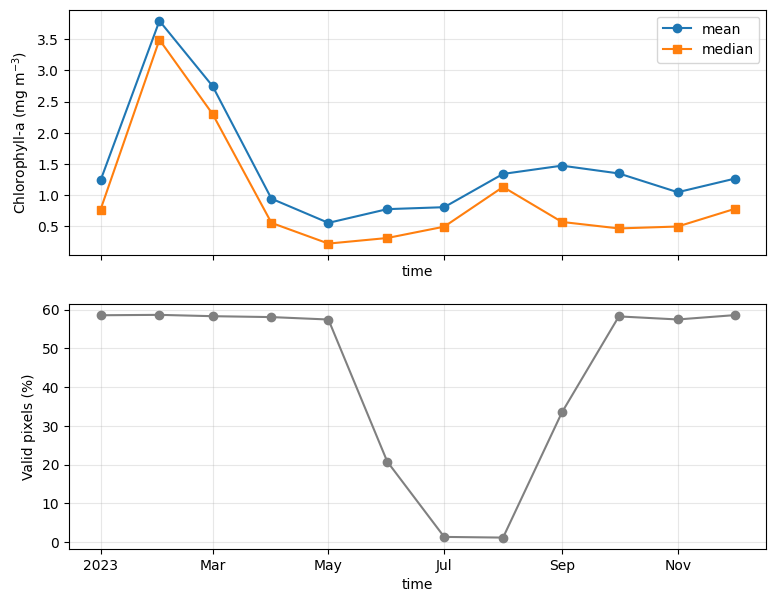

In [5]:
mean   = chl.mean(["lat", "lon"], skipna=True)
median = chl.median(["lat", "lon"], skipna=True)
valid  = chl.notnull().mean(["lat", "lon"]) * 100

fig, ax = plt.subplots(2, 1, figsize=(9, 7), sharex=True)
mean.plot(ax=ax[0], marker="o", label="mean")
median.plot(ax=ax[0], marker="s", label="median")
ax[0].set_ylabel("Chlorophyll-a (mg m$^{-3}$)")
ax[0].legend(); ax[0].grid(alpha=0.3)

valid.plot(ax=ax[1], marker="o", color="gray")
ax[1].set_ylabel("Valid pixels (%)")
ax[1].grid(alpha=0.3)
plt.show()

## 6. Mausami (seasonal) maps

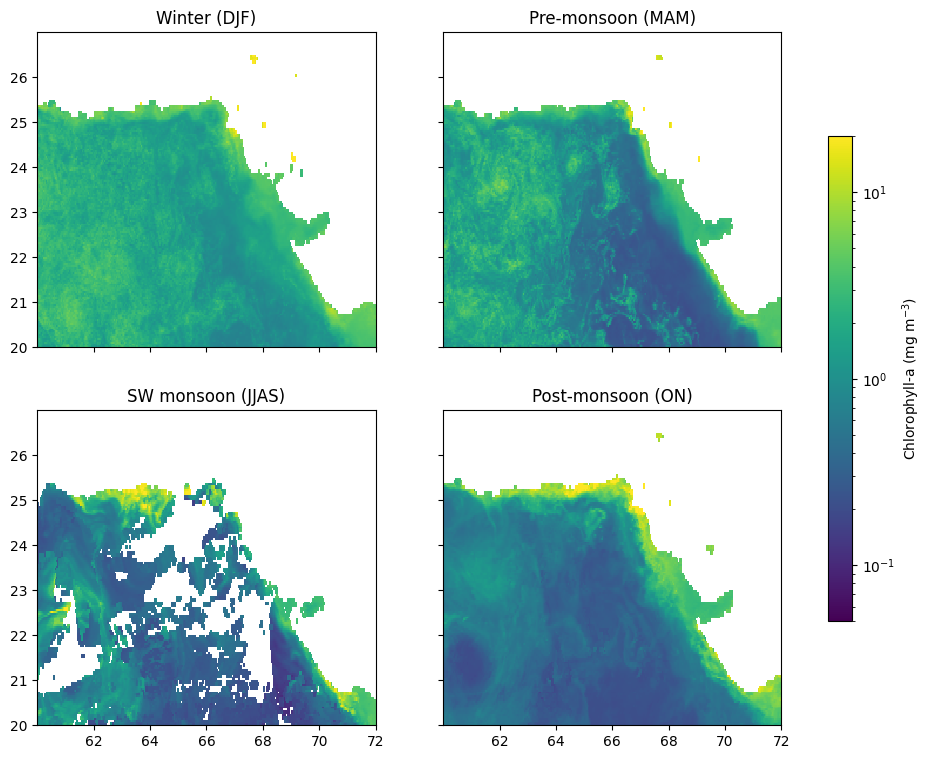

In [6]:
seasons = {
    "Winter (DJF)":        [12, 1, 2],
    "Pre-monsoon (MAM)":   [3, 4, 5],
    "SW monsoon (JJAS)":   [6, 7, 8, 9],
    "Post-monsoon (ON)":   [10, 11],
}

fig, axes = plt.subplots(2, 2, figsize=(12, 9), sharex=True, sharey=True)
for ax, (name, months) in zip(axes.flat, seasons.items()):
    s = chl.sel(time=chl.time.dt.month.isin(months)).mean("time", skipna=True)
    im = s.plot(ax=ax, cmap="viridis", norm=norm, add_colorbar=False)
    ax.set_title(name)
    ax.set_xlabel(""); ax.set_ylabel("")
fig.colorbar(im, ax=axes, shrink=0.7, label="Chlorophyll-a (mg m$^{-3}$)")
plt.show()

## 7. Latitude-time diagram (Hovmöller)
Har mahine ke liye longitude ka average, taake pata chale bloom kis latitude par kab aya.

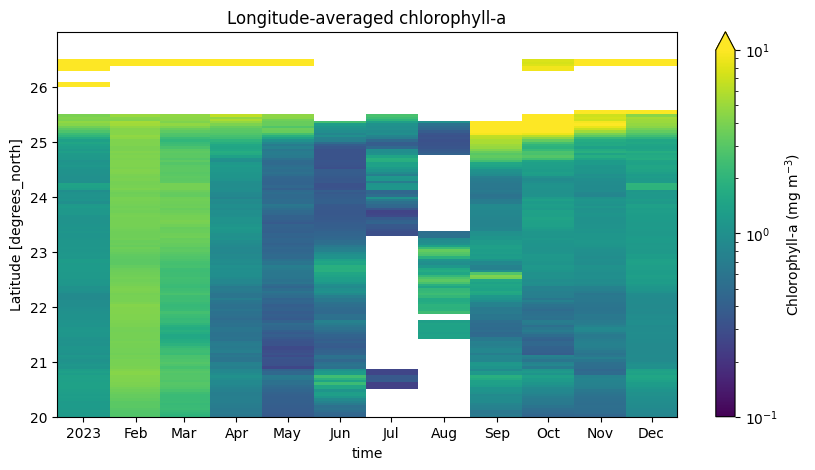

In [7]:
hov = chl.mean("lon", skipna=True)
plt.figure(figsize=(10, 5))
hov.plot(x="time", y="lat", cmap="viridis", norm=LogNorm(vmin=0.1, vmax=10),
         cbar_kwargs={"label": "Chlorophyll-a (mg m$^{-3}$)"})
plt.title("Longitude-averaged chlorophyll-a")
plt.show()

## 8. Coast vs gehra samundar
Boxes apni marzi se badlo `(west, east, south, north)`.

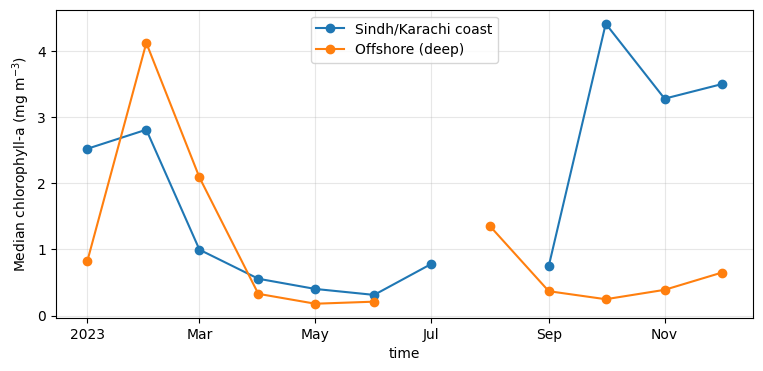

In [8]:
boxes = {
    "Sindh/Karachi coast": (66.5, 68.0, 23.5, 25.0),
    "Offshore (deep)":     (62.0, 66.0, 20.0, 22.0),
}

plt.figure(figsize=(9, 4))
for name, (w, e, s, n) in boxes.items():
    ts = chl.sel(lon=slice(w, e), lat=slice(n, s)).median(["lat", "lon"], skipna=True)
    ts.plot(marker="o", label=name)
plt.ylabel("Median chlorophyll-a (mg m$^{-3}$)")
plt.legend(); plt.grid(alpha=0.3)
plt.show()

## 9. Ek khaas jagah ka time series
Latitude/longitude badal ke apni jagah dekho. Pixel NaN ho to thoda samundar ki taraf jao.

Nearest pixel: 24.520832061767578 66.68750762939453
Valid months: 11 / 12


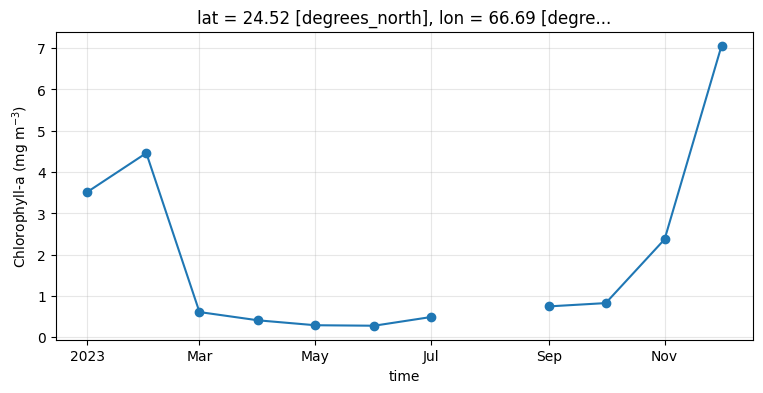

In [9]:
LAT, LON = 24.5, 66.7      # Karachi ke samne samundar
pt = chl.sel(lat=LAT, lon=LON, method="nearest")
print("Nearest pixel:", float(pt.lat), float(pt.lon))
print("Valid months:", int(pt.notnull().sum()), "/ 12")

plt.figure(figsize=(9, 4))
pt.plot(marker="o")
plt.ylabel("Chlorophyll-a (mg m$^{-3}$)")
plt.grid(alpha=0.3)
plt.show()

## 10. Anomaly map: kisi mahine ka saal ke average se farq
Positive = us mahine zyada chlorophyll, negative = kam. Ratio use kiya hai kyunke chlorophyll log scale par chalta hai.

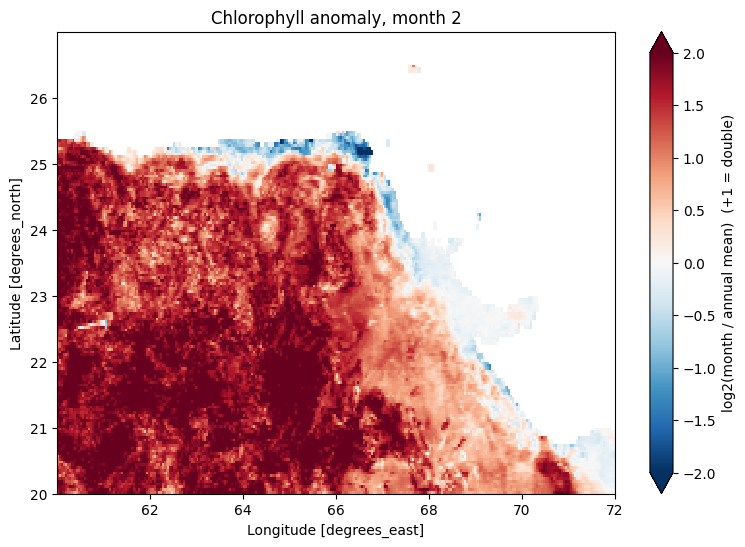

In [10]:
MONTH = 2   # February
annual = chl.mean("time", skipna=True)
ratio = chl.isel(time=MONTH - 1) / annual

plt.figure(figsize=(9, 6))
np.log2(ratio).plot(cmap="RdBu_r", vmin=-2, vmax=2,
                    cbar_kwargs={"label": "log2(month / annual mean)  (+1 = double)"})
plt.title(f"Chlorophyll anomaly, month {MONTH}")
plt.show()